In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

In [66]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

## MNIST 숫자 손글씨를 앙상블(랜덤 포레스트) 알고리즘에 사용할 데이터를 준비한다.

MNIST 숫자 손글씨 데이터셋을 불러온다.

In [4]:
raw_data = datasets.load_digits()
raw_data

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)),
 'target': array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7'

In [6]:
print(raw_data.data[0])

[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


In [13]:
print(type(raw_data.images[0]))
print(raw_data.images[0])

<class 'numpy.ndarray'>
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


MNIST 숫자 손글씨 이미지 시각화

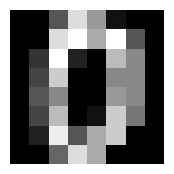

In [11]:
plt.figure(figsize=[2, 2])
plt.imshow(raw_data.images[0], cmap=plt.cm.gray)
plt.axis('off')
plt.show()

MNIST 손글씨 숫자 데이터를 피처와 레이블로 불러온다.

In [12]:
x_train = raw_data.data
print(x_train)
y_train = raw_data.target
print(y_train)
print(x_train.shape, y_train.shape)

[[ 0.  0.  5. ...  0.  0.  0.]
 [ 0.  0.  0. ... 10.  0.  0.]
 [ 0.  0.  0. ... 16.  9.  0.]
 ...
 [ 0.  0.  1. ...  6.  0.  0.]
 [ 0.  0.  2. ... 12.  0.  0.]
 [ 0.  0. 10. ... 12.  1.  0.]]
[0 1 2 ... 8 9 8]
(1797, 64) (1797,)


## 배열 차원 변경

넘파이의 reshape(), resize(), ravel() 메소드는 넘파이 배열의 차원(shape)을 변경한다.

넘파이의 arange() 메소드의 사용 방법은 파이썬의 range() 함수와 같고 range() 함수는 리스트를 만들지만 arange() 메소드는 넘파이 배열을 만든다.

In [31]:
a = np.arange(24)
print(type(a))
print(a)
print(a.shape)

<class 'numpy.ndarray'>
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
(24,)


In [32]:
b = a.reshape(4, 6)
print(b)

[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]
 [12 13 14 15 16 17]
 [18 19 20 21 22 23]]


넘파이의 배열을 차원을 변경하는 메소드는 기본적으로 얕은 복사가 실행된다. 얕은 복사란 실제 데이터를 복사하는것이 아니고 데이터가 저장된 메모리의 주소만 넘겨주는 것을 의미한다.

`사본의 데이터를 수정하면 원본의 데이터도 같이 수정`된다. => 부작용(side effect) 현상이 발생된다.

In [35]:
b[1][2] = 999

In [36]:
print(b)

[[  0   1   2   3   4   5]
 [  6   7 999   9  10  11]
 [ 12  13  14  15  16  17]
 [ 18  19  20  21  22  23]]


In [37]:
print(a)

[  0   1   2   3   4   5   6   7 999   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23]


reshape() 메소드와 resize() 메소드는 shape을 변경하는 부분에서는 동일하다.

In [54]:
a = np.arange(12)
print(a)

[ 0  1  2  3  4  5  6  7  8  9 10 11]


In [55]:
# reshape() 메소드는 메소드를 실행하는 원본 배열을 변경하지 않는다.
print(a.reshape(2, 6))

[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]


In [56]:
print(a)

[ 0  1  2  3  4  5  6  7  8  9 10 11]


In [57]:
b = np.arange(12)
print(b)

[ 0  1  2  3  4  5  6  7  8  9 10 11]


In [58]:
# resize() 메소드는 메소드를 실행하는 원본 배열을 변경한다.
print(b.resize(2, 6))

None


In [59]:
print(b)

[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]


reshape() 메소드는 원본과 데이터의 개수가 일치하지 않으면 에러가 발생되고 resize() 메소드는 남는 자리는 0이 채워지고 모자라면 데이터가 분실된다.

In [63]:
# a = np.arange(12).reshape(2, 10) # ValueError: cannot reshape array of size 12 into shape (2,10) 에러가 발생된다.
b = np.arange(12)
b.resize(2, 10)
print(b)
c = np.arange(12)
c.resize(2, 4)
print(c)

[[ 0  1  2  3  4  5  6  7  8  9]
 [10 11  0  0  0  0  0  0  0  0]]
[[0 1 2 3]
 [4 5 6 7]]


ravel() 메소드는 배열을 무조건 1차원 배열로 만든다.

In [65]:
a = np.arange(12).reshape(2, 6)
print(a)
b = a.ravel()
print(b)

[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]
[ 0  1  2  3  4  5  6  7  8  9 10 11]


1차원을 2차원으로 변경할 때는 reshape(행, 열) 메소드를 사용하고 2차원을 1차원으로 변경할 때는 ravel() 메소드를 사용한다.

## 의사결정 트리와 랜덤 포레스트 알고리즘을 교차 검증을 통해서 모델의 정확도를 비교한다.

교차 검증 정확도를 계산하는 함수를 만든다.

In [67]:
def cross_validation(model, x_train, y_train):
    scores = []
    for i in range(10):
        score = cross_val_score(model, x_train, y_train, scoring='accuracy', cv=10)
        scores.append(score.mean())
    return scores

의사결정 트리의 MNIST 손글씨 숫자 데이터의 검증 정확도를 계산한다.

In [71]:
score_dt = cross_validation(DecisionTreeClassifier(), x_train, y_train)
for score in score_dt:
    print(f'{score:.5f}', end=' ')

0.82358 0.82636 0.82578 0.83638 0.83583 0.82246 0.82858 0.82467 0.82302 0.82971 

랜덤 포레스트의 MNIST 손글씨 숫자 데이터의 검증 정확도를 계산한다.

In [72]:
score_rf = cross_validation(RandomForestClassifier(), x_train, y_train)
for score in score_rf:
    print(f'{score:.5f}', end=' ')

0.94379 0.94881 0.94713 0.94491 0.95157 0.95158 0.95103 0.95047 0.94825 0.94880 

In [78]:
print(f'의사결정 트리: {np.mean(score_dt):.2%}')
print(f'랜덤 포레스트: {np.mean(score_rf):.2%}')

의사결정 트리: 82.76%
랜덤 포레스트: 94.86%


## 의사결정 트리와 랜덤 포레스트의 검증 정확도 시각화

In [79]:
df = pd.DataFrame({'의사결정 트리': score_dt, '랜덤 포레스트': score_rf})
df

,의사결정 트리,랜덤 포레스트
0,0.823575,0.943790
1,0.826359,0.948808
2,0.825779,0.947132
3,0.836378,0.944910
4,0.835826,0.951574
5,0.822458,0.951577
6,0.828582,0.951030
7,0.824674,0.950472
8,0.823023,0.948250
9,0.829711,0.948799


<Figure size 800x600 with 0 Axes>

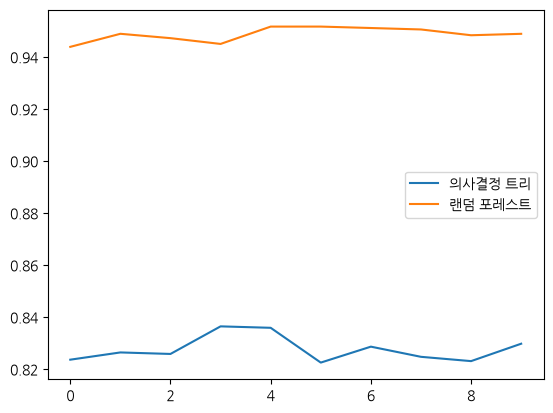

In [80]:
plt.figure(figsize=[8, 6])
df.plot()
plt.show()